In [1]:
"""Demonstrate the factory-based charged coagulation workflow with particula.

The tutorial constructs a charged particle size distribution, derives supporting
transport properties, obtains a charged strategy through CoagulationFactory, and
visualizes the resulting kernel on a log-log grid.

Examples:
    >>> par.dynamics.CoagulationFactory().get_strategy(
    ...     "charged",
    ...     parameters={"distribution_type": "discrete",
    ...                 "charged_kernel_strategy": par.dynamics.CoulombGatti2008KernelStrategy()},
    ... )
"""

'Demonstrate the factory-based charged coagulation workflow with particula.\n\nThe tutorial constructs a charged particle size distribution, derives supporting\ntransport properties, obtains a charged strategy through CoagulationFactory, and\nvisualizes the resulting kernel on a log-log grid.\n\nExamples:\n    >>> par.dynamics.CoagulationFactory().get_strategy(\n    ...     "charged",\n    ...     parameters={"distribution_type": "discrete",\n    ...                 "charged_kernel_strategy": par.dynamics.CoulombGatti2008KernelStrategy()},\n    ... )\n'

# Coagulation with Charge (Functional + Factory)
This tutorial demonstrates the functional workflow for charged coagulation using the public factory API in `particula.dynamics`. We:
- define a charged particle size distribution,
- compute required transport properties,
- obtain a charged coagulation strategy via `CoagulationFactory`, and
- visualize the resulting coagulation kernel.

In [2]:
import matplotlib.pyplot as plt
import numpy as np
import particula as par

plt.rcParams["figure.dpi"] = 110

## Define the particle size distribution
Logarithmic grid (1 nm to 100 μm) with unit-density mass bins.

In [3]:
radius_bins = np.logspace(start=-9, stop=-4, num=250)  # m (1 nm to 100 μm)
mass_bins = 4 / 3 * np.pi * radius_bins**3 * 1e3  # kg (ρ = 1000 kg/m³)
n_bins = len(radius_bins)

## Assign particle charges
Negative charges cover the first third; positive charges cover the remaining two thirds.

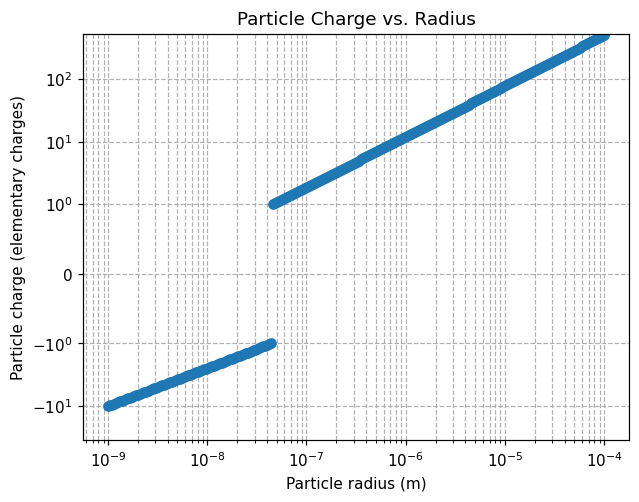

In [4]:
split_index = n_bins // 3
neg_charges = -np.logspace(np.log10(10), np.log10(1), num=split_index)
pos_charges = np.logspace(np.log10(1), np.log10(500), num=n_bins - split_index)
charge_array = np.concatenate((neg_charges, pos_charges))

fig, ax = plt.subplots()
ax.plot(radius_bins, charge_array, marker="o", linestyle="none")
ax.set_xscale("log")
ax.set_yscale("symlog", linthresh=1)
ax.set_xlabel("Particle radius (m)")
ax.set_ylabel("Particle charge (elementary charges)")
ax.set_title("Particle Charge vs. Radius")
ax.grid(True, which="both", ls="--")
plt.show()

## Supporting properties
Compute Coulomb potential ratio, gas properties, Knudsen numbers, slip correction, friction factor, and helper matrices.

In [5]:
temperature = 298.15  # K

coulomb_potential_ratio: np.ndarray = np.asarray(
    par.particles.get_coulomb_enhancement_ratio(
        radius_bins, charge_array, temperature=temperature
    ),
    dtype=float,
)
dynamic_viscosity = par.gas.get_dynamic_viscosity(temperature=temperature)
mol_free_path = par.gas.get_molecule_mean_free_path(
    temperature=temperature, dynamic_viscosity=dynamic_viscosity
)
knudsen_number = par.particles.get_knudsen_number(
    mean_free_path=mol_free_path, particle_radius=radius_bins
)
slip_correction = par.particles.get_cunningham_slip_correction(
    knudsen_number=knudsen_number
)
friction_factor_value = par.particles.get_friction_factor(
    particle_radius=radius_bins,
    dynamic_viscosity=dynamic_viscosity,
    slip_correction=slip_correction,
)
diffusive_knudsen_values: np.ndarray = np.asarray(
    par.particles.get_diffusive_knudsen_number(
        particle_radius=radius_bins,
        particle_mass=mass_bins,
        friction_factor=friction_factor_value,
        coulomb_potential_ratio=coulomb_potential_ratio,
        temperature=temperature,
    ),
    dtype=float,
)

sum_of_radii = radius_bins[:, np.newaxis] + radius_bins[np.newaxis, :]
reduced_mass = par.util.get_reduced_self_broadcast(mass_bins)
reduced_friction_factor = par.util.get_reduced_self_broadcast(
    friction_factor_value
)

## Get a charged coagulation strategy via factory
Use `CoagulationFactory` with the charged type and a Coulomb kernel strategy. The factory builds the underlying charged coagulation strategy using the provided parameters.

In [6]:
factory = par.dynamics.CoagulationFactory()
kernel_strategy = par.dynamics.CoulombGatti2008KernelStrategy()
coagulation_strategy = factory.get_strategy(
    "charged",
    parameters={
        "distribution_type": "discrete",
        "charged_kernel_strategy": kernel_strategy,
    },
)

dimensionless_kernel = coagulation_strategy.kernel_strategy.dimensionless(
    diffusive_knudsen=diffusive_knudsen_values,
    coulomb_potential_ratio=coulomb_potential_ratio,
)
dimensional_kernel = coagulation_strategy.kernel_strategy.kernel(
    dimensionless_kernel=dimensionless_kernel,
    coulomb_potential_ratio=coulomb_potential_ratio,
    sum_of_radii=sum_of_radii,
    reduced_mass=reduced_mass,
    reduced_friction_factor=reduced_friction_factor,
)

/home/kyle/Code/particula/particula/dynamics/coagulation/charged_dimensionless_kernel.py:203: RuntimeWarning: divide by zero encountered in divide
  factored_term = (pi_sqrt * continuum * coulomb_potential_ratio * 1.22) / (
/home/kyle/Code/particula/particula/dynamics/coagulation/charged_dimensionless_kernel.py:208: RuntimeWarning: invalid value encountered in multiply
  term1 = continuum_limit * (1 - (1 + factored_term) * exponential_decay)
/home/kyle/Code/particula/particula/dynamics/coagulation/charged_dimensionless_kernel.py:214: RuntimeWarning: divide by zero encountered in divide
  + (
/home/kyle/Code/particula/particula/dynamics/coagulation/charged_dimensionless_kernel.py:210: RuntimeWarning: invalid value encountered in multiply
  np.sqrt(8 * np.pi)


## Visualize the kernel
This broad charge/radius range produces underflow warnings in intermediate
expressions. The final kernel is finite and nonnegative; exactly zero
entries are masked on the logarithmic plot, not replaced by positive values.
Plot the dimensional coagulation kernel returned by the factory-built strategy.

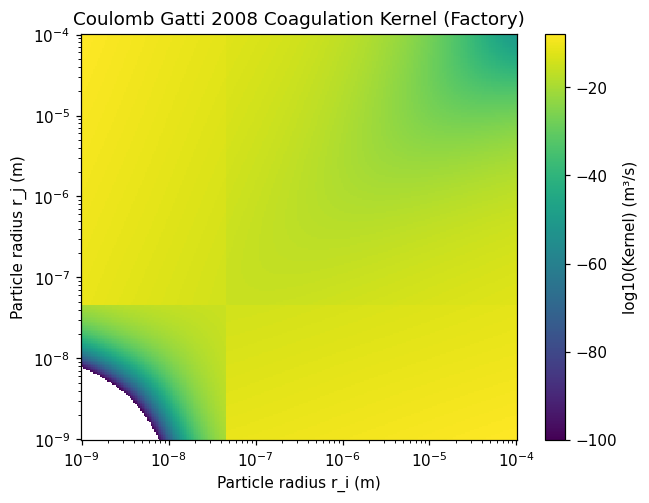

In [7]:
assert np.all(np.isfinite(dimensional_kernel))
assert np.all(dimensional_kernel >= 0)
np.testing.assert_allclose(
    dimensional_kernel, dimensional_kernel.T, rtol=1e-12, atol=0
)
log_kernel = np.ma.log10(np.ma.masked_less_equal(dimensional_kernel, 0))
fig, ax = plt.subplots()
mesh = ax.pcolormesh(radius_bins, radius_bins, log_kernel, shading="auto")
ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlabel("Particle radius r_i (m)")
ax.set_ylabel("Particle radius r_j (m)")
ax.set_title("Coulomb Gatti 2008 Coagulation Kernel (Factory)")
fig.colorbar(mesh, ax=ax, label="log10(Kernel) (m³/s)")
plt.show()